# recuperation index gutendex

Test comparatif du temps **recuperation reseau** et du temps **de recuperation en cache**

In [8]:
import runpy
import time
from pathlib import Path

runpy.run_path(str(next(p / "ipynb.py" for p in (Path.cwd(), *Path.cwd().parents) if (p / "ipynb.py").is_file())), init_globals=globals())

import matplotlib.pyplot as plt

from nlp_pipeline import config
from nlp_pipeline.retrieval import gutendex
from nlp_pipeline.storage import cache

config.ensure_directories()
BOOK_ID = 11

In [9]:
sup = cache.clear("all")
print("cache vidé :", sup)

cache vidé : {'books': 0, 'cache': 0, 'output': 0}


In [10]:
def chronometrer(fn) -> tuple[float, dict]:
    debut = time.perf_counter()
    resultat = fn()
    return (time.perf_counter() - debut) * 1000, resultat

In [11]:
ms_reseau, index = chronometrer(lambda: gutendex.fetch(BOOK_ID, use_cache=False))
print(f"reseau: {ms_reseau:.0f} ms {index['title']}")
print(f"fichier cache créé")

reseau: 16231 ms Alice's Adventures in Wonderland
fichier cache créé


In [12]:
ms_cache, index_cache = chronometrer(lambda: gutendex.fetch(BOOK_ID, use_cache=True))
print(f"cache: {ms_cache:.0f} ms {index_cache['title']}")
assert index_cache["id"] == index["id"]
print("meme livre")

cache: 0 ms Alice's Adventures in Wonderland
meme livre


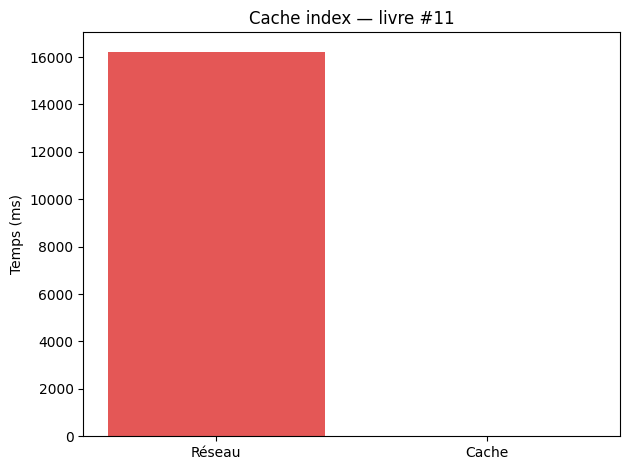

In [ ]:
labels = ["Réseau", "Cache"]
valeurs = [ms_reseau, ms_cache]

plt.bar(labels, valeurs, color=["#E45756", "#54A24B"])
plt.ylabel("Temps (ms)")
plt.title(f"Cache index livre #{BOOK_ID}")
plt.tight_layout()
plt.show()